# Cartografía de incendios forestales con Sentinel-2

En este cuaderno, queremos mostrar un caso de uso de cartografía de incendios forestales usando Sentinel-2 siguiendo el método discutido en el trabajo de Nolde et al. (2020)(https://www.mdpi.com/2072-4292/12/13/2162#). Aquí, queremos replicar sólo una parte del flujo de trabajo. Así, se trata de calcular las diferencias sin nubes en el NDVI para los datos anteriores y posteriores al incendio y compararlos.
#

Se estudian grandes incendios forestales en Chile, especialmente en las regiones de Biobío y La Araucanía. El objetivo del estudio fue analizar cómo cambia la vegetación antes y después del fuego usando imágenes satelitales Sentinel-2, comparando NDVI y otros índices.

In [ ]:
# libs
!pip install openeo
!pip install matplotlib
!pip install rasterio
!pip install scipy
!pip install folium

  Using cached openeo-0.43.0-py3-none-any.whl.metadata (7.7 kB)
  Using cached xarray-2025.1.1-py3-none-any.whl.metadata (11 kB)
  Using cached pystac-1.13.0-py3-none-any.whl.metadata (4.7 kB)
  Using cached Deprecated-1.2.18-py2.py3-none-any.whl.metadata (5.7 kB)
Using cached openeo-0.43.0-py3-none-any.whl (315 kB)
Using cached Deprecated-1.2.18-py2.py3-none-any.whl (10.0 kB)
Using cached pystac-1.13.0-py3-none-any.whl (206 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 9.4 MB/s eta 0:00:00a 0:00:01
Using cached xarray-2025.1.1-py3-none-any.whl (1.2 MB)

[notice] A new release of pip is available: 24.3.1 -> 25.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 24.3.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
  Using cached affine-2.4.0-py3-none-any.whl.metadata (4.0 kB)
  Using cached attrs-25.3.0-py3-none-any.whl.metadata (10 kB)
  Using cached click-8.2.1-py3-none-any.whl.metadata (2.5 kB)
  Using cached cli

In [1]:
import scipy
import numpy as np

import openeo
from openeo.extra.spectral_indices import compute_indices

import matplotlib.pyplot as plt
import matplotlib
import matplotlib.patches as mpatches
import rasterio
from rasterio.plot import show

Para este caso de uso seleccionamos una zona de Chile, próximo a la población de Quirihue, donde se registró un incendio en el mes de febrero de 2023.

In [4]:
# import openeo
# connection = openeo.connect("openeo.dataspace.copernicus.eu").authenticate_basic(username="mfbarrientos@uvg.edu.gt")

OpenEoClientException: This openEO back-end does not support basic authentication.

In [7]:
import openeo
connection = openeo.connect("openeo.dataspace.copernicus.eu").authenticate_oidc()

Visit https://identity.dataspace.copernicus.eu/auth/realms/CDSE/device?user_code=AKXL-ASGV 📋 to authenticate.

✅ Authorized successfully

Authenticated using device code flow.


In [8]:
print (connection)
extent = {"west": -72.69, "south": -36.34, "east": -72.51, "north": -36.15}
extent

<Connection to 'https://openeo.dataspace.copernicus.eu/openeo/1.2/' with OidcBearerAuth>


{'west': -72.69, 'south': -36.34, 'east': -72.51, 'north': -36.15}

##### ¿Dónde estamos?

In [10]:
import folium

# Coordenadas del centro del área
center_lat = (extent["north"] + extent["south"]) / 2
center_lon = (extent["east"] + extent["west"]) / 2

# Crear el mapa centrado en esa ubicación
m = folium.Map(location=[center_lat, center_lon], zoom_start=12)

# Agregar el rectángulo del área
folium.Rectangle(
    bounds=[
        [extent["south"], extent["west"]],
        [extent["north"], extent["east"]]
    ],
    color="red",
    fill=True,
    fill_opacity=0.2,
    tooltip="Área de análisis (incendio)"
).add_to(m)
print(center_lat, center_lon)
# Mostrar el mapa
m

-36.245000000000005 -72.6


Como los lugares con incendios forestales suelen estar cubiertos de nubes, lo que dificulta el cálculo de las zonas afectadas por los incendios forestales, queremos obtener un cubo de datos pre-evento libre de nubes. Por lo tanto, vamos a definir una sencilla función Python para pre-procesar el NDVI pre-evento. Aquí utilizamos el concepto de BAP que significa los mejores píxeles libres de nubes disponibles justo antes o justo después del evento de incendio forestal, esto se obtiene a través del enmascaramiento de nubes y la reducción temporal con «primero» en el datacube post evento y «último» en el datacube pre evento.ent date.

Así pues: 
* En primer lugar, creamos una máscara de nubes con una banda SCL en la que filtramos los píxeles que tienen un efecto de nube; 
* A continuación, se crea un núcleo gaussiano, ya que las máscaras de nubes suelen tener ruido y es posible que no abarquen completamente la región de nubes; 
* A continuación, aplicamos una función de suavizado a la máscara seleccionada junto con una dilatación morfométrica para aumentar y suavizar el área de la máscara. En este caso, para la dilatación, seleccionamos 11 píxeles; 
* A continuación, se produce una máscara binaria aplicando un umbral de 0,1. Esto implica que, para ser clasificados como píxeles libres de nubes, los píxeles que han sido sometidos a suavizado y dilatación deben presentar un valor inferior a 0,1. 
* Una vez generada la máscara requerida, se aplica un umbral de 0,1. 
* Una vez generada la máscara necesaria, se aplica al cubo de datos; 
* Por último, una vez que se dispone del cubo de datos enmascarado, queremos seleccionar cada píxel libre de nubes lo más cerca posible de la fecha del incendio forestal. Para conseguirlo, reducimos la dimensión temporal (reduce_dimension) basándonos en el criterio «last», que selecciona el píxel libre de nubes más cercano a la fecha del suceso.e.

In [11]:
# define a function to identify cloud-free pixels in the available data-cube
"""
scl: es la banda llamada Scene Classification Layer del satélite Sentinel-2. Sirve para saber si un píxel es vegetación, sombra, agua, nube, etc.
data: es el cubo de datos con la información real (como NDVI, por ejemplo).
reducer: es cómo vamos a escoger el "mejor píxel". "first" toma el más temprano; "last" el más cercano a la fecha del evento.

Queremos ver qué pasó con la vegetación antes y después de un incendio, pero las imágenes de satélite muchas veces están tapadas por nubes. 
Entonces lo que hace esta función es filtrar las imágenes y quedarse solo con los pedacitos sin nubes, y de esos, elegir el más cercano 
a la fecha del incendio. Así obtenemos una imagen lo más limpia posible para comparar cambios en la vegetación.
"""

def getBAP(scl, data, reducer="first"):
    mask = (scl == 3) | (scl == 8) | (scl == 9) | (scl == 10)

    # mask is a bit noisy, so we apply smoothening
    # 2D gaussian kernel
    g = scipy.signal.windows.gaussian(11, std=1.6)
    kernel = np.outer(g, g)
    kernel = kernel / kernel.sum()

    # Morphological dilation of mask: convolution + threshold
    mask = mask.apply_kernel(kernel)
    mask = mask > 0.1

    data_masked = data.mask(mask)

    # now select Best Available Pixel based on the mask
    return data_masked.reduce_dimension(reducer=reducer, dimension="t")

## Utilización del índice de vegetación de diferencia normalizada (NDVI)

### NDVI anterior al evento

Carguemos Sentinel-2 L2A como nuestro cubo de datos previo al evento para calcular el NDVI.

In [12]:
# load S2 pre-collection
s2pre = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=["2023-01-15", "2023-01-25"],
    spatial_extent=extent,
    bands=["B04", "B08", "B12"],
    max_cloud_cover=90,
)

s2pre_scl = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=["2023-01-15", "2023-01-25"],
    spatial_extent=extent,
    bands=["SCL"],
    max_cloud_cover=90,
)

# calculate ndvi
ndvi_pre = s2pre.ndvi()

In [14]:
# Create a Pre-event cloud free mosiac
ndvi_pre = getBAP(s2pre_scl, ndvi_pre, reducer="last")

In [15]:
ndvi_pre.download("NDVI.tiff")

In [1]:
ndvi_pre_array = ndvi_pre.read(1)
print(ndvi_pre_array)
print(ndvi_pre_array.shape)


NameError: name 'ndvi_pre' is not defined

In [37]:
print(ndvi_pre.transform)

| 10.00, 0.00, 707310.00|
| 0.00,-10.00, 5996950.00|
| 0.00, 0.00, 1.00|


#### Observación:
El archivo que descargaste (NDVI.tiff) no es una imagen normal como una foto, sino un raster científico: cada píxel tiene un valor numérico entre aproximadamente -1 y 1. Como no tiene una paleta de colores definida, muchos visores estándar muestran todo como una escala de grises:
* Valores bajos (NDVI cercano a -1) → píxeles oscuros o negros
* Valores altos (NDVI cercano a 1) → píxeles blancos.ndvi_pre
#
Cada píxel indica qué tan verde o saludable está la vegetación en ese lugar:
* Zonas quemadas, urbanas o sin vegetación → valores bajos (negros o grises oscuros).
* Zonas con bosques o cultivos verdes → valores altos (blancos o grises claros).


------

Durante un incendio forestal, queremos conocer su ubicación lo antes posible. Sin embargo, esto significa que las imágenes suelen estar llenas de humo y nubes justo después de los incendios, lo que dificulta su rendimiento con muchos píxeles cubiertos de nubes en los que no podemos cartografiar el incendio forestal.

Por lo tanto, aquí queremos mostrar dos modos de funcionamiento:

(i) Modo NRT y (ii) Modo post-evento. En el modo NRT, intentamos cartografiar basándonos en la primera imagen disponible justo después del incendio forestal. En el modo post-evento, realizamos un preprocesamiento similar al de los datos pre-evento para obtener imágenes libres de nubes. El modo NRT se utiliza generalmente para la primera respuesta y acciones rápidas, mientras que el modo post se utiliza para estudios científicos.

### Modo casi en tiempo real (NRT) NDVI

In [17]:
# load S2 Near-real-time(NRT) collection
s2nrt = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=["2023-02-20", "2023-02-28"],
    spatial_extent=extent,
    bands=["B04", "B08", "B12"],
    max_cloud_cover=90,
)

s2nrt_scl = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=["2023-02-20", "2023-02-28"],
    spatial_extent=extent,
    bands=["SCL"],
    max_cloud_cover=90,
)

ndvi_nrt = s2nrt.ndvi()
ndvi_nrt = getBAP(s2nrt_scl, ndvi_nrt, reducer="first")

Ahora que disponemos de datos NDVI anteriores y posteriores al suceso, calculamos el dNDVI (NDVI diferencial) para localizar los lugares en los que se ha producido un incendio forestal.

In [18]:
# download NDVI for NRT mode for comparison
ndvi_nrt.download("NRT_NDVI.tiff")

In [19]:
# download signal of fire in near real time
fire_nrt = ndvi_pre - ndvi_nrt
fire_nrt.download("NRT_Fire.tiff")

### NDVI posterior al evento

En el modo posterior al suceso, de forma similar a los datos anteriores al suceso, recopilamos series temporales de imágenes a largo plazo y preparamos los datos para calcular píxeles de NDVI sin nubes. En particular, aquí utilizamos el reductor como «primero» principalmente porque se trata de una serie temporal posterior al suceso, y nos gustaría obtener un píxel libre de nubes con NDVI lo antes posible desde el suceso del incendio forestal, por lo que seleccionar el primer píxel libre de nubes disponible garantiza que obtengamos el píxel libre de nubes más temprano.

In [20]:
# load S2 post collection
s2post = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=["2023-03-04", "2023-03-14"],
    spatial_extent=extent,
    bands=["B04", "B08", "B12"],
    max_cloud_cover=90,
)

s2post_scl = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=["2023-03-04", "2023-03-14"],
    spatial_extent=extent,
    bands=["SCL"],
    max_cloud_cover=90,
)

# calculate post ndvi mosaic
ndvi_post = s2post.ndvi()
ndvi_post = getBAP(s2post_scl, ndvi_post, reducer="first")

In [21]:
# download NDVI for post-event mode for comparison
ndvi_post.download("Post_NDVI.tiff")

In [22]:
fire_mosiac = ndvi_pre - ndvi_post
fire_mosiac.download("Mosiac_Fire.tiff")

### Trazar el NDVI

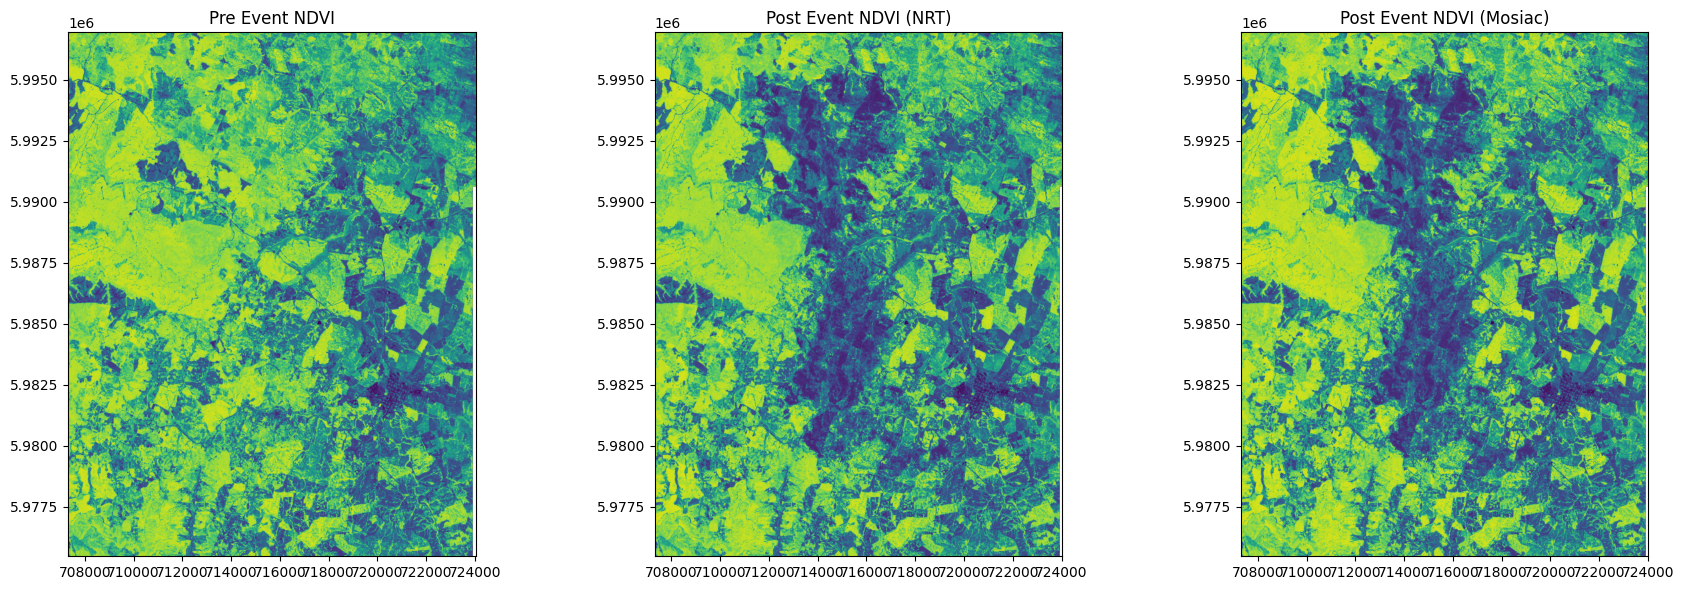

In [23]:
ndvi = rasterio.open("NDVI.tiff")
ndvi_nrt = rasterio.open("NRT_NDVI.tiff")
ndvi_mosiac = rasterio.open("Post_NDVI.tiff")

f, axarr = plt.subplots(1, 3, dpi=100, figsize=(18, 6))
im = show(ndvi.read(1), vmin=0, vmax=1, transform=ndvi.transform, ax=axarr[0])
axarr[0].set_title("Pre Event NDVI")

im = show(ndvi_nrt.read(1), vmin=0, vmax=1, transform=ndvi_nrt.transform, ax=axarr[1])
axarr[1].set_title("Post Event NDVI (NRT)")

im = show(
    ndvi_mosiac.read(1), vmin=0, vmax=1, transform=ndvi_mosiac.transform, ax=axarr[2]
)
axarr[2].set_title("Post Event NDVI (Mosiac)")
plt.tight_layout()

Como podemos ver, hay un descenso del NDVI en los lugares con incendios forestales (véase el final de la página para la verdad sobre el terreno). Esto demuestra que con el enfoque adoptado podemos identificar los lugares con incendios forestales.

Por otra parte, también podemos observar que en el modo NDVI NRT y el modo NDVI Mosiac no hay mucha diferencia, la razón podría ser porque la nubosidad no estaba presente en la imagen NRT. Esto demuestra que si no hay nubosidad, ambos modos funcionan de forma similar. Ahora, basándonos en estas imágenes hemos calculado la diferencia en el NDVI, que es la localización probable de un incendio forestal; vamos a visualizarlas también..



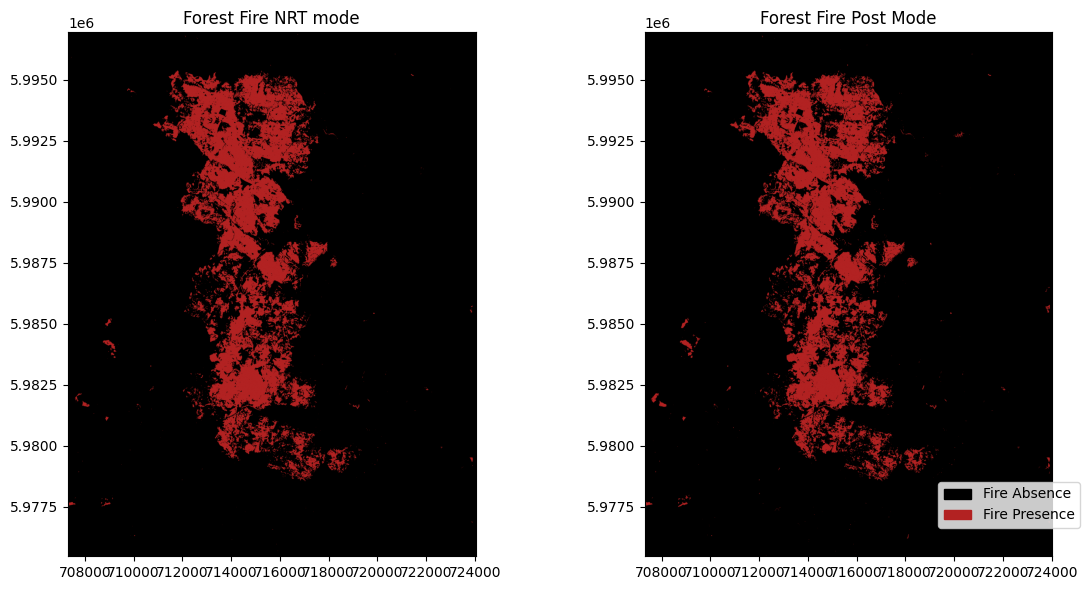

In [24]:
fire_nrt = rasterio.open("NRT_Fire.tiff")
fire_mosiac = rasterio.open("Mosiac_Fire.tiff")

cmap = matplotlib.colors.ListedColormap(["black", "firebrick"])
values = ["Absence", "Presence"]
colors = ["black", "firebrick"]

f, axarr = plt.subplots(1, 2, dpi=100, figsize=(12, 6))

im = show(
    fire_nrt.read(1) > 0.3,
    vmin=0,
    vmax=1,
    transform=fire_nrt.transform,
    ax=axarr[0],
    cmap=cmap,
)
axarr[0].set_title("Forest Fire NRT mode")

im = show(
    fire_mosiac.read(1) > 0.3,
    vmin=0,
    vmax=1,
    transform=fire_mosiac.transform,
    ax=axarr[1],
    cmap=cmap,
)
axarr[1].set_title("Forest Fire Post Mode")
patches = [
    mpatches.Patch(color=colors[i], label="Fire {l}".format(l=values[i]))
    for i in range(len(values))
]
f.legend(handles=patches, bbox_to_anchor=(0.95, 0.2), loc=1)
plt.tight_layout()

Aquí, podemos ver que el área quemada está bastante bien cartografiada en ambos modos y comparada con la imagen de la verdad sobre el terreno mostrada al final de este cuaderno, la cartografía del área quemada es bastante precisa. Por otra parte, esto todavía se puede mejorar con los datos NBR, según lo sugerido por Nolde et al.(2020). Intentemos lo mismo con NBR.

## Con Ratio de Quemado Normalizado (NBR)

Todo este proceso también se puede realizar con NBR, ya que el documento (https://www.mdpi.com/2072-4292/12/13/2162#) sugiere que NBR produce una mayor precisión, pero debido a la falta de disponibilidad de la banda SWIR en los satélites de resolución media, optaron por utilizar NDVI.

Citado: «Opcionalmente, el sistema puede utilizar el índice Normalized Burn Ratio (NBR) ([40], véanse las ecuaciones (3) y (4)) en lugar del NDVI. Este índice presenta capacidades superiores para la discriminación de áreas quemadas en comparación con el NDVI».

Por lo tanto, en este cuaderno, también mostramos el mismo proceso anterior con NBR. En este caso, todos los pasos de procesamiento son los mismos excepto el cálculo del NBR en lugar del NDVI.


In [25]:
nbr_pre = compute_indices(s2pre, indices=["NBR"])
nbr_pre = getBAP(s2pre_scl, nbr_pre, reducer="last")

In [26]:
nbr_pre.download("NBR.tiff")

### Modo NRT para NBR

In [27]:
nbr_nrt = compute_indices(s2nrt, indices=["NBR"])
nbr_nrt = getBAP(s2nrt_scl, nbr_nrt, reducer="first")

In [28]:
nbr_nrt.download("NRT_NBR.tiff")

In [29]:
# download signal of fire in near real-time
fire_nrt_nbr = nbr_pre - nbr_nrt
fire_nrt_nbr.download("NRT_NBR_Fire.tiff")

### Modo post-evento para NBR

In [30]:
nbr_post = compute_indices(s2post, indices=["NBR"])
nbr_post = getBAP(s2post_scl, nbr_post, reducer="first")

In [31]:
nbr_post.download("Post_NBR.tiff")

In [32]:
fire_nrt_mosiac = nbr_pre - nbr_post
fire_nrt_mosiac.download("Mosiac_NBR_Fire.tiff")

### Trazar el NBR

Ahora tenemos la NBR y su diferencia, que puede tratarse como un indicador indirecto de los incendios forestales. Visualicémoslos, primero la RBN sola y luego el mapa de incendios forestales a partir de ella.

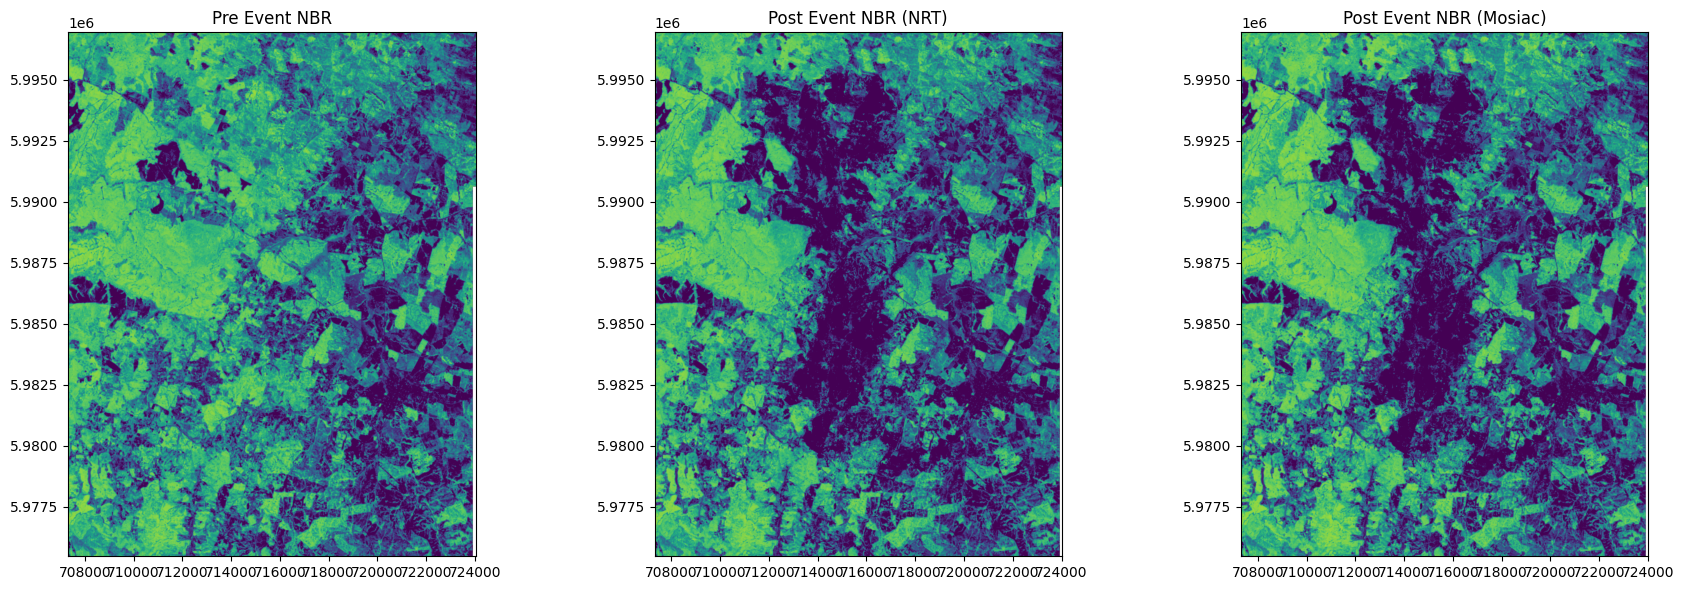

In [33]:
nbr = rasterio.open("NBR.tiff")
nbr_nrt = rasterio.open("NRT_NBR.tiff")
nbr_mosiac = rasterio.open("Post_NBR.tiff")

f, axarr = plt.subplots(1, 3, dpi=100, figsize=(18, 6))
im = show(nbr.read(1), vmin=0, vmax=1, transform=nbr.transform, ax=axarr[0])
axarr[0].set_title("Pre Event NBR")

im = show(nbr_nrt.read(1), vmin=0, vmax=1, transform=nbr_nrt.transform, ax=axarr[1])
axarr[1].set_title("Post Event NBR (NRT)")

im = show(
    nbr_mosiac.read(1), vmin=0, vmax=1, transform=nbr_mosiac.transform, ax=axarr[2]
)
axarr[2].set_title("Post Event NBR (Mosiac)")
plt.tight_layout()

Como podemos ver, la localización del incendio forestal es bastante prominente en las imágenes NBR posteriores al evento en comparación con la de las imágenes NBR anteriores al evento. Esto demuestra que el enfoque con NBR tiene mejor visibilidad de las señales de incendio forestal que el enfoque basado en NDVI. Veamos ahora cómo queda el resultado final de la zona del incendio forestal con la imagen de diferencia NBR.

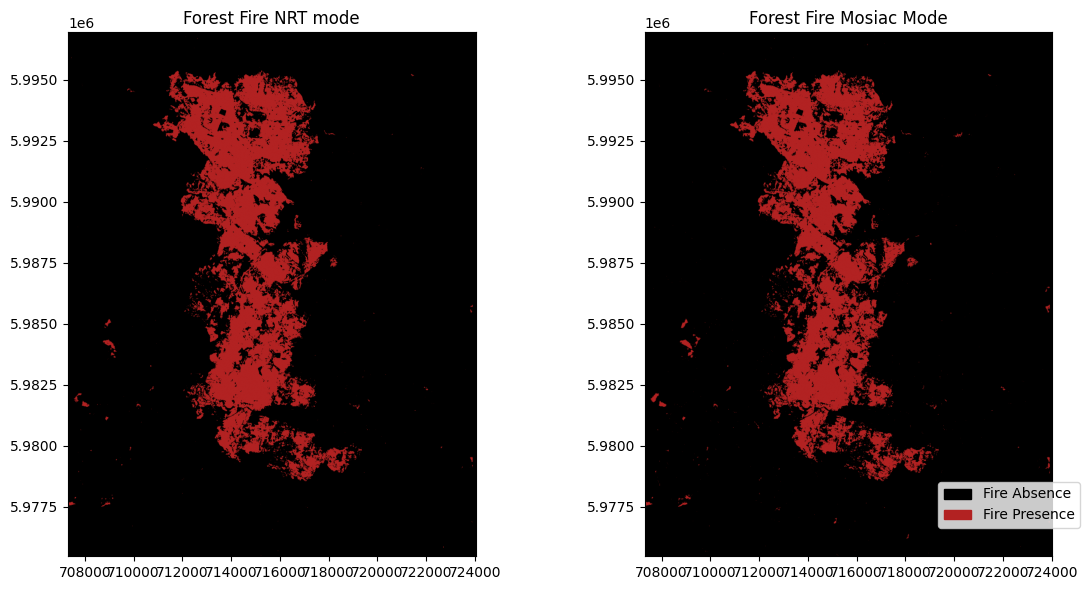

In [34]:
fire_nbr_nrt = rasterio.open("NRT_NBR_Fire.tiff")
fire_nbr_mosiac = rasterio.open("Mosiac_NBR_Fire.tiff")

cmap = matplotlib.colors.ListedColormap(["black", "firebrick"])
values = ["Absence", "Presence"]
colors = ["black", "firebrick"]

f, axarr = plt.subplots(1, 2, dpi=100, figsize=(12, 6))

im = show(
    fire_nbr_nrt.read(1) > 0.3,
    vmin=0,
    vmax=1,
    transform=fire_nbr_nrt.transform,
    ax=axarr[0],
    cmap=cmap,
)
axarr[0].set_title("Forest Fire NRT mode")

im = show(
    fire_nbr_mosiac.read(1) > 0.3,
    vmin=0,
    vmax=1,
    transform=fire_nbr_mosiac.transform,
    ax=axarr[1],
    cmap=cmap,
)
axarr[1].set_title("Forest Fire Mosiac Mode")
patches = [
    mpatches.Patch(color=colors[i], label="Fire {l}".format(l=values[i]))
    for i in range(len(values))
]
f.legend(handles=patches, bbox_to_anchor=(0.95, 0.2), loc=1)
plt.tight_layout()

Podemos ver aquí que con el uso de NBR, el mapa final del área del incendio forestal parece mucho más completo y menos ruidoso/pixelado en comparación con el enfoque basado en NDVI. En general, podemos ver que tanto el enfoque basado en NDVI como el basado en NBR son buenos para la cartografía de incendios forestales en tiempo casi real, así como para el análisis posterior al evento. Estos datos pueden utilizarse para la planificación, mitigación y gestión de la prevención de incendios forestales.

### Verdad terreno

Como ejemplo de verdad terreno en el ejercicio original realizado en Jaen, España tenemos esta cartografía. 

![Cartografía final](https://documentation.dataspace.copernicus.eu/APIs/openEO/openeo-community-examples/python/ForestFire/gt.png)

![Copernicus](https://www.copernicus.eu/themes/custom/copernicus/logo.svg)